In [8]:
from google.colab import files

uploaded = files.upload()

In [9]:
import pandas as pd


ruta_archivo = '/content/Consolidado_ambiental_nodos_Comuna_22_AD.xlsx'

df = pd.read_excel(ruta, sheet_name="Datos semanales")
dic = pd.read_excel(ruta, sheet_name="Diccionario")


,nodo,latitud,longitud,inicio_semana,fin_semana,año,semana,temperatura_media_c,humedad_media_pct,radiacion_media,...,lecturas_mass,cobertura_mass_pct,cobertura_min_pct,precipitacion_semana_previa,precipitacion_2sem_previas,precipitacion_4sem_previas,temperatura_2sem_previas_c,humedad_2sem_previas_pct,pm25_2sem_previas,huevos_aedes
0,1,3.346428,-76.554549,2023-06-26,2023-07-02,2023,26,24.531510,71.789583,178.333333,...,192,28.571429,28.571429,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,1,3.346428,-76.554549,2023-07-03,2023-07-09,2023,27,22.781701,83.757249,140.286982,...,677,100.000000,100.000000,0.0,NaN,NaN,NaN,NaN,NaN,58.0
2,1,3.346428,-76.554549,2023-07-10,2023-07-16,2023,28,24.067917,76.865327,173.269345,...,672,100.000000,100.000000,89.4,89.4,NaN,23.656606,77.773416,8.998701,46.0
3,1,3.346428,-76.554549,2023-07-17,2023-07-23,2023,29,24.664851,64.334375,178.489583,...,672,100.000000,100.000000,0.4,89.8,NaN,23.424809,80.311288,12.629579,80.0
4,1,3.346428,-76.554549,2023-07-24,2023-07-30,2023,30,24.383348,73.572321,164.047619,...,672,100.000000,100.000000,0.0,0.4,89.8,24.366384,70.599851,11.373065,38.0


In [20]:
import numpy as np


In [10]:
print(df.shape) # fase de conocimiento de los datos
print(df.dtypes.value_counts()) # cuantos tipos de variables hay y cuantos hay de cada una
print(df.groupby("nodo").size())# agrupar los datos por nodo para su mejor procesamiento
print(sorted(set(range(1, 19)) - set(df["nodo"])))# cuales nodos faltan
print(df["inicio_semana"].min(), df["inicio_semana"].max())# que periodo cubre el estudio cual es el rango

(2873, 49)
float64           38
int64              9
datetime64[ns]     2
Name: count, dtype: int64
nodo
1     169
2     169
3     169
4     169
5     169
6     169
7     169
8     169
10    169
11    169
12    169
13    169
14    169
15    169
16    169
17    169
18    169
dtype: int64
[9]
2023-06-26 00:00:00 2026-09-14 00:00:00


In [11]:
print("Filas duplicadas:", df.duplicated().sum())# cuantos datos duplicados hay
print("Duplicados nodo+semana:", df.duplicated(["nodo", "inicio_semana"]).sum()) #cuenta repeticiones del mismo nodo en la misma semana; cada combinación debe ser única

iso = df["inicio_semana"].dt.isocalendar() # calcula año y semana ISO a partir de la fecha; sirve para verificar las columnas año y semana
print("No lunes:", (df["inicio_semana"].dt.dayofweek != 0).sum()) # cuenta fechas de inicio que no son lunes (lunes = 0); deben ser 0 según el diccionario
print("fin != inicio+6:", ((df["fin_semana"] - df["inicio_semana"]).dt.days != 6).sum()) # cuenta semanas que no duran 7 días (inicio + 6 = fin); deben ser 0
print("Año/semana ISO inconsistentes:", # cuenta filas donde año o semana no coinciden con la fecha; deben ser 0
      ((iso.year != df["año"]) | (iso.week != df["semana"])).sum())

Filas duplicadas: 0
Duplicados nodo+semana: 0
No lunes: 0
fin != inicio+6: 0
Año/semana ISO inconsistentes: 0


In [12]:
falt = df.isna().sum().to_frame("n_NA")  # cuenta los vacíos (NA) de cada columna y los pone en una tabla
falt["pct"] = (falt["n_NA"] / len(df) * 100).round(2)  # convierte ese conteo en porcentaje del total de filas; permite comparar columnas
print(falt[falt["n_NA"] > 0])  # muestra solo las columnas que sí tienen faltantes; evita imprimir 49 líneas
print("Filas con algún NA:", df.isna().any(axis=1).sum())  # cuenta filas con al menos un vacío; dice cuántas observaciones están incompletas
print(df.isna().sum(axis=1).groupby(df["nodo"]).sum())  # suma los vacíos por nodo; revela si el problema se concentra en pocos sensores (15 y 16)

                             n_NA   pct
temperatura_media_c             9  0.31
humedad_media_pct               9  0.31
radiacion_media                 9  0.31
uv_media                        9  0.31
viento_medio                    4  0.14
ruido_medio_db                  5  0.17
pm25_media                      5  0.17
pm10_media                      5  0.17
temperatura_min_c               9  0.31
humedad_min_pct                 9  0.31
viento_min                      4  0.14
ruido_min_db                    5  0.17
pm25_min                        5  0.17
pm10_min                        5  0.17
temperatura_max_c               9  0.31
humedad_max_pct                 9  0.31
radiacion_max                   9  0.31
uv_max                          9  0.31
viento_max                      4  0.14
ruido_max_db                    5  0.17
pm25_max                        5  0.17
pm10_max                        5  0.17
amplitud_termica_c              9  0.31
precipitacion_semanal           4  0.14


In [13]:
grupos = {  # diccionario con los tres valores de cada variable (mínimo, media, máximo)
    "temperatura": ("temperatura_min_c", "temperatura_media_c", "temperatura_max_c"),  # temperatura
    "humedad": ("humedad_min_pct", "humedad_media_pct", "humedad_max_pct"),  # humedad relativa
    "viento": ("viento_min", "viento_medio", "viento_max"),  # velocidad del viento
    "ruido": ("ruido_min_db", "ruido_medio_db", "ruido_max_db"),  # ruido en decibelios
    "pm25": ("pm25_min", "pm25_media", "pm25_max"),  # material particulado fino
    "pm10": ("pm10_min", "pm10_media", "pm10_max"),  # material particulado grueso
}  # cierra el diccionario
for nombre, (mn, md, mx) in grupos.items():  # recorre cada variable con su mínimo, media y máximo
    mal = (df[mn] > df[md]) | (df[md] > df[mx])  # marca las filas donde el mínimo supera a la media o la media supera al máximo (imposible)
    print(nombre, int(mal.sum()))  # imprime cuántas filas incoherentes tiene cada variable
print("PM2.5 media > PM10 media:", (df["pm25_media"] > df["pm10_media"]).sum())  # PM2.5 está contenido en PM10, así que su media no puede ser mayor

temperatura 0
humedad 1
viento 0
ruido 0
pm25 0
pm10 0
PM2.5 media > PM10 media: 3


       temperatura_media_c  humedad_media_pct  radiacion_media  pm25_media  \
count              2864.00            2864.00          2864.00     2868.00   
mean                 25.72              74.85           173.19       11.94   
std                  24.73               7.01            68.49       22.93   
min                  21.39               0.00             0.00        0.00   
25%                  23.73              70.29           145.92        7.45   
50%                  24.63              75.43           170.78       10.17   
75%                  25.56              79.76           191.26       12.69   
max                 615.25              95.80           756.73      505.58   

       ruido_medio_db  huevos_aedes  
count         2868.00       2801.00  
mean            51.27         79.30  
std              7.91        115.95  
min             34.50          0.00  
25%             45.36          0.00  
50%             49.01         47.00  
75%             58.35        11

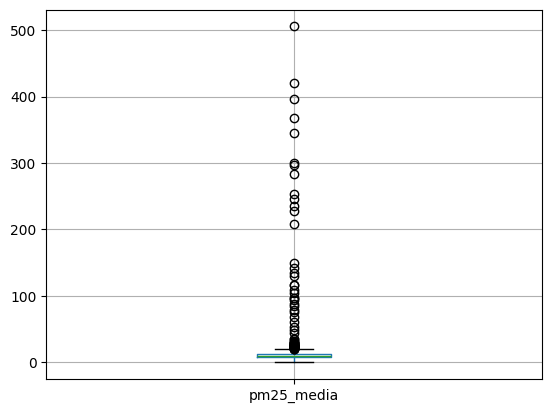

In [17]:
import matplotlib.pyplot as plt  # librería para hacer gráficos

print(df[["temperatura_media_c", "humedad_media_pct", "radiacion_media", "pm25_media", "ruido_medio_db", "huevos_aedes"]].describe().round(2))  # resumen (promedio, mínimo, máximo) de las variables clave; los máximos absurdos se ven aquí
print("Temperatura > 50:", (df["temperatura_max_c"] > 50).sum())  # cuenta temperaturas imposibles (6)
print("Humedad media = 0:", (df["humedad_media_pct"] == 0).sum())  # cuenta humedades medias de 0 % (5)
print("Radiación media = 0:", (df["radiacion_media"] == 0).sum())  # cuenta radiaciones medias de 0 (2)
print("PM2.5 máximo = 1000:", (df["pm25_max"] == 1000).sum())  # cuenta semanas donde PM2.5 llegó al tope del sensor (114)
df.boxplot(column="pm25_media")  # dibuja un boxplot de PM2.5; los puntos aislados arriba son valores atípicos
plt.show()  # muestra el gráfico en pantalla

In [18]:
print("Lecturas > 672:", (df["lecturas_surth"] > 672).sum())  # cuenta semanas con más lecturas de las posibles en 7 días (288)
print("Cobertura < 50 %:", (df["cobertura_min_pct"] < 50).sum())  # cuenta semanas con menos de la mitad de las lecturas (131)
print("Cobertura = 0 %:", (df["cobertura_min_pct"] == 0).sum())  # cuenta semanas sin ninguna lectura (3)

Lecturas > 672: 288
Cobertura < 50 %: 131
Cobertura = 0 %: 3


In [25]:
# 1) Temperatura imposible
fila_mala = df["temperatura_max_c"] > 50  # busca las filas donde la temperatura máxima pasa de 50 °C; en Cali eso es imposible, es error del sensor
df.loc[fila_mala, ["temperatura_media_c", "temperatura_min_c", "temperatura_max_c", "amplitud_termica_c"]] = np.nan  # en esas filas deja vacías las 4 columnas de temperatura; la amplitud también, porque se calcula con la temperatura dañada
df.loc[df["temperatura_2sem_previas_c"] > 50, "temperatura_2sem_previas_c"] = np.nan  # el error también se coló en el promedio de las 2 semanas previas; se borra para que no se propague

# 2) Humedad imposible
df.loc[df["humedad_media_pct"] == 0, "humedad_media_pct"] = np.nan  # una semana no puede tener humedad promedio de 0 %, así que se deja vacía

# 3) Radiación imposible
df.loc[df["radiacion_media"] == 0, "radiacion_media"] = np.nan  # una semana no puede tener radiación promedio de 0, así que se deja vacía

# Guardar
df.to_excel("base_limpia.xlsx", index=False)  # guarda la base limpia en un Excel nuevo; el archivo original no se modifica